In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv(
    r"C:\Users\Anindita\OneDrive\Desktop\credit-risk-prediction\data\processed\application_train_featured.csv"
)

print(df.shape)

(307511, 130)


In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_YEARS,EMPLOYMENT_YEARS,EMPLOYED_ANOMALY,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,INCOME_PER_FAMILY_MEMBER,CHILDREN_RATIO
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0.0,1.0,25.920548,1.745205,0,2.007889,0.121978,1.158397,202500.0,0.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0.0,0.0,45.931507,3.254795,0,4.790750,0.132217,1.145199,135000.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0.0,0.0,52.180822,0.616438,0,2.000000,0.100000,1.000000,67500.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,NaN,NaN,52.068493,8.326027,0,2.316167,0.219900,1.052803,67500.0,0.0
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0.0,0.0,54.608219,8.323288,0,4.222222,0.179963,1.000000,121500.0,0.0


In [4]:
X = df.drop("TARGET", axis=1)

In [5]:
y = df["TARGET"]

In [6]:
X.shape

(307511, 129)

In [7]:

X = X.drop("SK_ID_CURR", axis=1)

In [8]:
X.shape

(307511, 128)

In [9]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

C:\Users\Anindita\AppData\Local\Temp\ipykernel_5588\1168470759.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [10]:
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 112
Categorical features: 16


In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [12]:
stratify=y

In [13]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (246008, 128)
Validation: (61503, 128)


In [14]:
print(y_train.value_counts(normalize=True))

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [15]:
print(y_val.value_counts(normalize=True))

TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [17]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [18]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        dtype=np.float32
    ))
])

In [19]:
# Reduce memory usage of numeric data
X_train = X_train.copy()
X_val = X_val.copy()

X_train[numeric_features] = X_train[numeric_features].astype(np.float32)
X_val[numeric_features] = X_val[numeric_features].astype(np.float32)

print("Numeric data converted to float32")

Numeric data converted to float32


In [20]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [21]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Training preprocessing completed!")
print("Shape:", X_train_processed.shape)

Training preprocessing completed!
Shape: (246008, 252)


In [22]:
X_val_processed = preprocessor.transform(X_val)

print("Validation preprocessing completed!")
print("Shape:", X_val_processed.shape)

Validation preprocessing completed!
Shape: (61503, 252)


In [23]:
print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (246008, 252)
Validation shape: (61503, 252)


In [24]:
import joblib
import os
joblib.dump(
    preprocessor,
    "../models/feature_preprocessor.pkl"
)

['../models/feature_preprocessor.pkl']

In [25]:
os.path.exists("../models/feature_preprocessor.pkl")

True

# Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

In [28]:
logistic_model.fit(
    X_train_processed,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [29]:
y_pred_proba = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

In [30]:
from sklearn.metrics import roc_auc_score

In [31]:
roc_auc = roc_auc_score(
    y_val,
    y_pred_proba
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.7491906734598412


In [32]:
y_pred = logistic_model.predict(X_val_processed)

In [33]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

In [34]:
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)

In [35]:
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.1617618772840931
Recall: 0.6775427995971802
F1 Score: 0.2611699856372035


In [36]:
from sklearn.metrics import average_precision_score

In [37]:
pr_auc = average_precision_score(
    y_val,
    y_pred_proba
)

print("PR-AUC:", pr_auc)

PR-AUC: 0.22821057053583949


In [38]:
results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "ROC-AUC": [roc_auc],
    "PR-AUC": [pr_auc],
    "Precision": [precision],
    "Recall": [recall],
    "F1": [f1]
})

results

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.749191,0.228211,0.161762,0.677543,0.26117


In [39]:
joblib.dump(
    logistic_model,
    "../models/logistic_regression.pkl"
)

['../models/logistic_regression.pkl']

In [40]:
os.path.exists("../models/logistic_regression.pkl")

True

In [41]:
from sklearn.ensemble import RandomForestClassifier

In [42]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [43]:
rf_model.fit(
    X_train_processed,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [44]:
rf_pred_proba = rf_model.predict_proba(
    X_val_processed
)[:, 1]

In [45]:
rf_roc_auc = roc_auc_score(
    y_val,
    rf_pred_proba
)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.7359452208474639


In [46]:
rf_pred = rf_model.predict(
    X_val_processed
)

In [47]:
rf_precision = precision_score(
    y_val,
    rf_pred
)

rf_recall = recall_score(
    y_val,
    rf_pred
)

rf_f1 = f1_score(
    y_val,
    rf_pred
)

In [48]:
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1 Score:", rf_f1)

Precision: 0.18272566371681415
Recall: 0.5198388721047331
F1 Score: 0.27040335254059716


In [49]:
rf_pr_auc = average_precision_score(
    y_val,
    rf_pred_proba
)

print("PR-AUC:", rf_pr_auc)

PR-AUC: 0.21560941542766038


In [50]:
results

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.749191,0.228211,0.161762,0.677543,0.26117


In [51]:
results = pd.concat([
    results,
    pd.DataFrame({
        "Model": ["Random Forest"],
        "ROC-AUC": [rf_roc_auc],
        "PR-AUC": [rf_pr_auc],
        "Precision": [rf_precision],
        "Recall": [rf_recall],
        "F1": [rf_f1]
    })
], ignore_index=True)

In [52]:
results

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.749191,0.228211,0.161762,0.677543,0.261170
1,Random Forest,0.735945,0.215609,0.182726,0.519839,0.270403


In [53]:
joblib.dump(
    rf_model,
    "../models/random_forest.pkl"
)

['../models/random_forest.pkl']

In [54]:
os.path.exists(
    "../models/random_forest.pkl"
)

True

In [55]:
results.sort_values(
    by="ROC-AUC",
    ascending=False
)

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.749191,0.228211,0.161762,0.677543,0.261170
1,Random Forest,0.735945,0.215609,0.182726,0.519839,0.270403


In [56]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [57]:
# Calculate class imbalance ratio

scale_pos_weight = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 11.38710976837865


In [58]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=-1, num_parallel_tree=None, ...)


In [59]:
xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

print("XGBoost training completed!")

XGBoost training completed!


In [60]:
xgb_pred_proba = xgb_model.predict_proba(
    X_val_processed
)[:, 1]

xgb_pred = xgb_model.predict(
    X_val_processed
)

print("Predictions generated!")

Predictions generated!


In [61]:
xgb_pred_proba

array([0.39514193, 0.30827278, 0.76333743, ..., 0.3636218 , 0.58641225,
       0.6412517 ], shape=(61503,), dtype=float32)

In [62]:
xgb_pred

array([0, 0, 1, ..., 0, 1, 1], shape=(61503,))

In [63]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

xgb_roc_auc = roc_auc_score(
    y_val,
    xgb_pred_proba
)

xgb_pr_auc = average_precision_score(
    y_val,
    xgb_pred_proba
)

xgb_precision = precision_score(
    y_val,
    xgb_pred
)

xgb_recall = recall_score(
    y_val,
    xgb_pred
)

xgb_f1 = f1_score(
    y_val,
    xgb_pred
)

print("XGBoost Results")
print("-------------------------")
print("ROC-AUC :", xgb_roc_auc)
print("PR-AUC  :", xgb_pr_auc)
print("Precision:", xgb_precision)
print("Recall  :", xgb_recall)
print("F1 Score:", xgb_f1)

XGBoost Results
-------------------------
ROC-AUC : 0.7619121533354016
PR-AUC  : 0.25369589614769694
Precision: 0.17157114929519499
Recall  : 0.6717019133937563
F1 Score: 0.27332704995287466


In [64]:
results = pd.concat([
    results,
    pd.DataFrame({
        "Model": ["XGBoost"],
        "ROC-AUC": [xgb_roc_auc],
        "PR-AUC": [xgb_pr_auc],
        "Precision": [xgb_precision],
        "Recall": [xgb_recall],
        "F1": [xgb_f1]
    })
], ignore_index=True)

results.sort_values(
    "ROC-AUC",
    ascending=False
)

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
2,XGBoost,0.761912,0.253696,0.171571,0.671702,0.273327
0,Logistic Regression,0.749191,0.228211,0.161762,0.677543,0.261170
1,Random Forest,0.735945,0.215609,0.182726,0.519839,0.270403


In [65]:
import joblib

joblib.dump(
    xgb_model,
    "../models/xgboost.pkl"
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [66]:
import shap

In [67]:
import joblib

xgb_model = joblib.load("../models/xgboost.pkl")

print("XGBoost model loaded successfully!")

XGBoost model loaded successfully!


In [68]:
explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [69]:
X_shap = X_val_processed[:5000]

print("SHAP dataset shape:", X_shap.shape)

SHAP dataset shape: (5000, 252)


In [70]:
shap_values = explainer(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


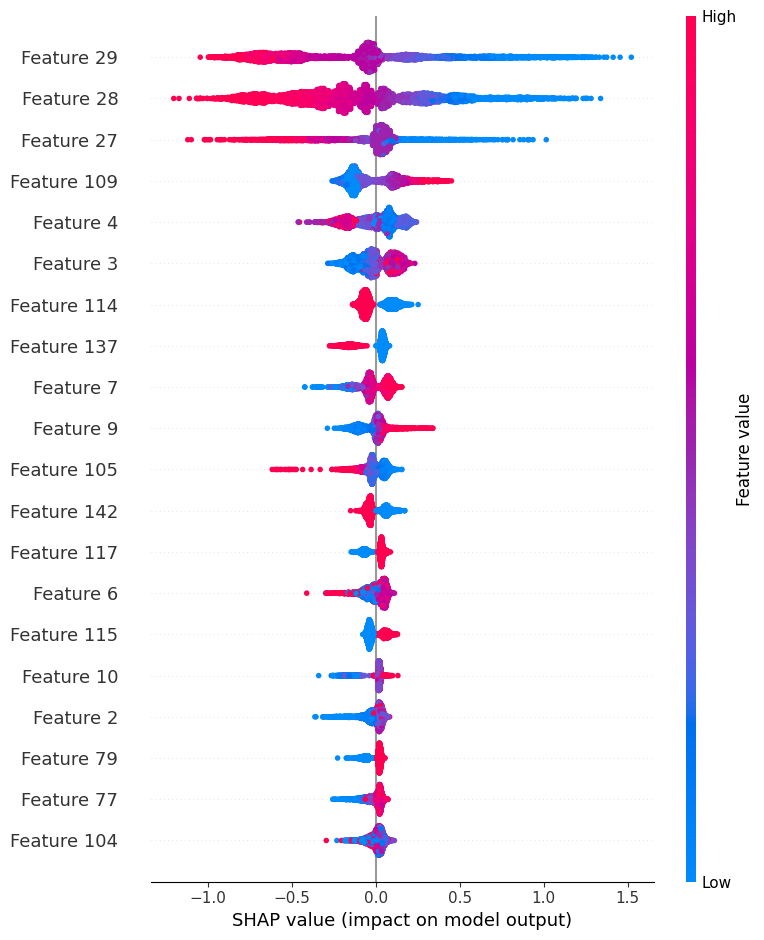

In [71]:
shap.summary_plot(
    shap_values,
    X_shap
)

In [72]:
print(shap_values.shape)

(5000, 252)


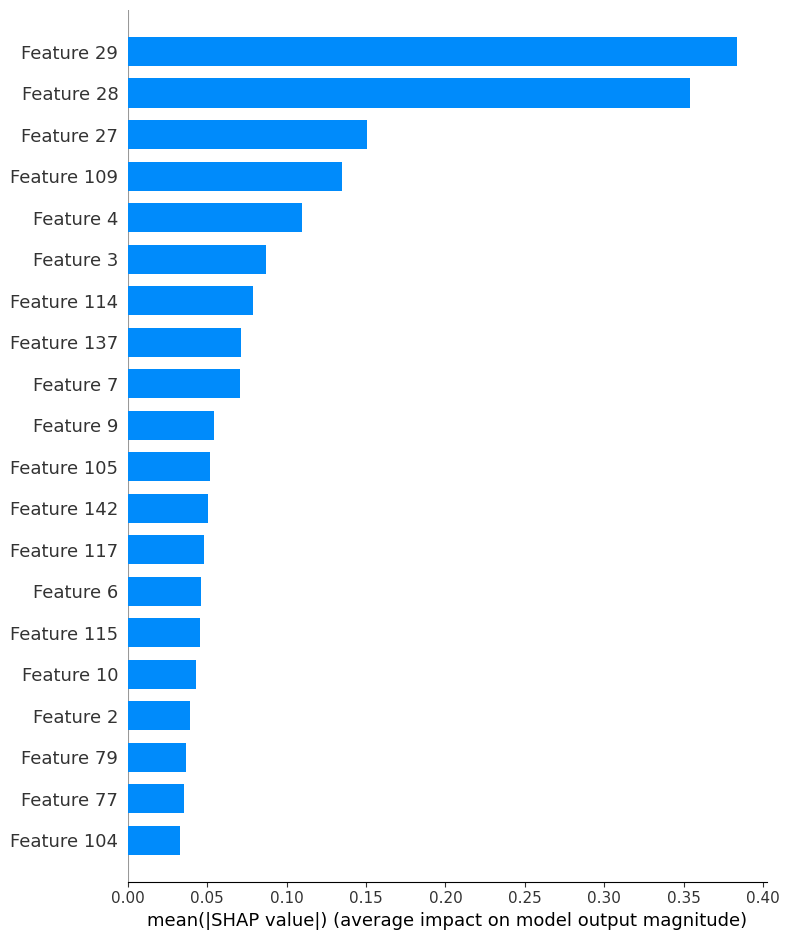

In [73]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)

In [74]:
import shap

In [75]:
import joblib

xgb_model = joblib.load("../models/xgboost.pkl")

In [76]:
explainer = shap.TreeExplainer(xgb_model)

In [77]:
X_shap = X_val_processed[:5000]

shap_values = explainer(X_shap)

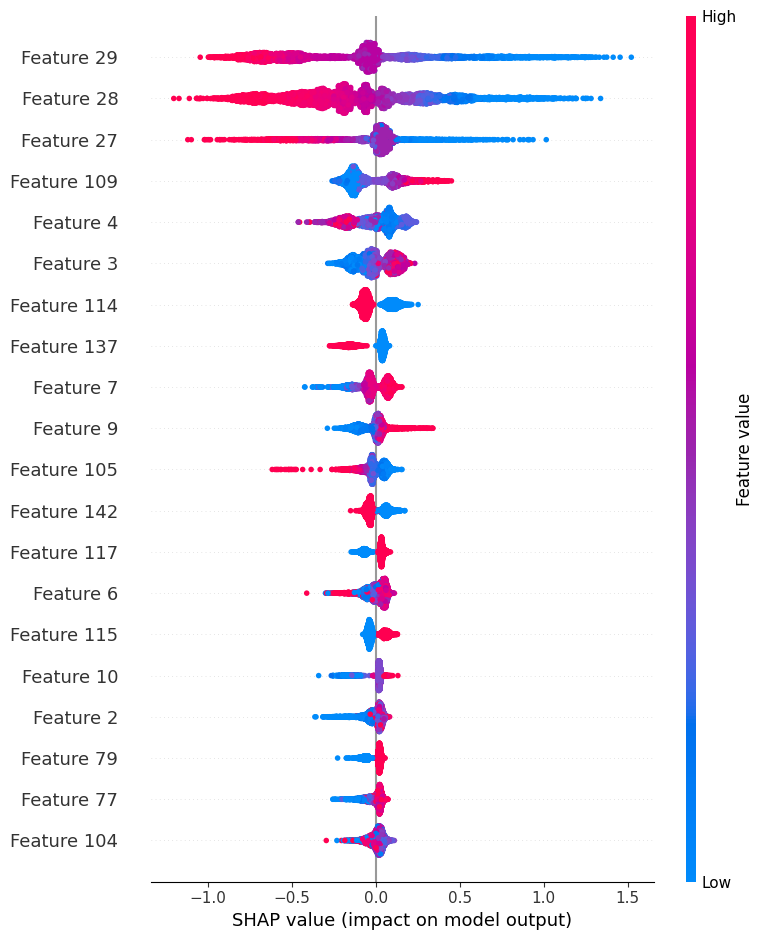

In [78]:
shap.summary_plot(
    shap_values,
    X_shap
)

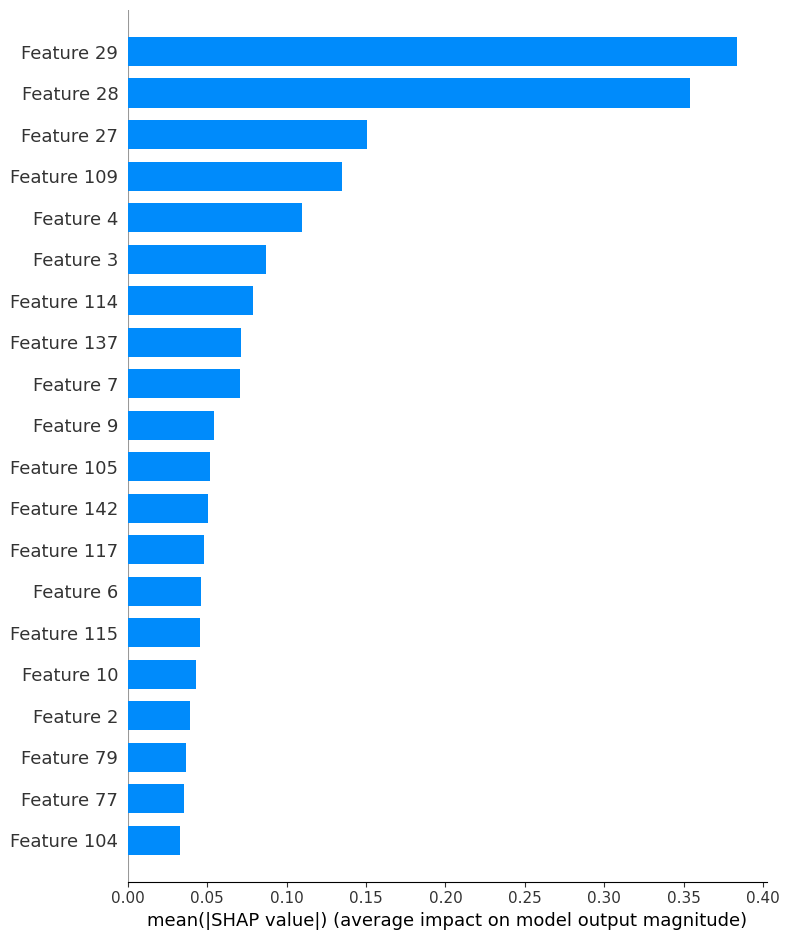

In [79]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)

In [80]:
import joblib

preprocessor = joblib.load(
    "../models/feature_preprocessor.pkl"
)

print("Preprocessor loaded successfully!")

Preprocessor loaded successfully!


In [81]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names[:20])

Number of features: 252
['num__CNT_CHILDREN' 'num__AMT_INCOME_TOTAL' 'num__AMT_CREDIT'
 'num__AMT_ANNUITY' 'num__AMT_GOODS_PRICE'
 'num__REGION_POPULATION_RELATIVE' 'num__DAYS_BIRTH' 'num__DAYS_EMPLOYED'
 'num__DAYS_REGISTRATION' 'num__DAYS_ID_PUBLISH' 'num__OWN_CAR_AGE'
 'num__FLAG_MOBIL' 'num__FLAG_EMP_PHONE' 'num__FLAG_WORK_PHONE'
 'num__FLAG_CONT_MOBILE' 'num__FLAG_PHONE' 'num__FLAG_EMAIL'
 'num__CNT_FAM_MEMBERS' 'num__REGION_RATING_CLIENT'
 'num__REGION_RATING_CLIENT_W_CITY']


In [82]:
print("X_shap shape:", X_shap.shape)
print("Feature names:", len(feature_names))

X_shap shape: (5000, 252)
Feature names: 252


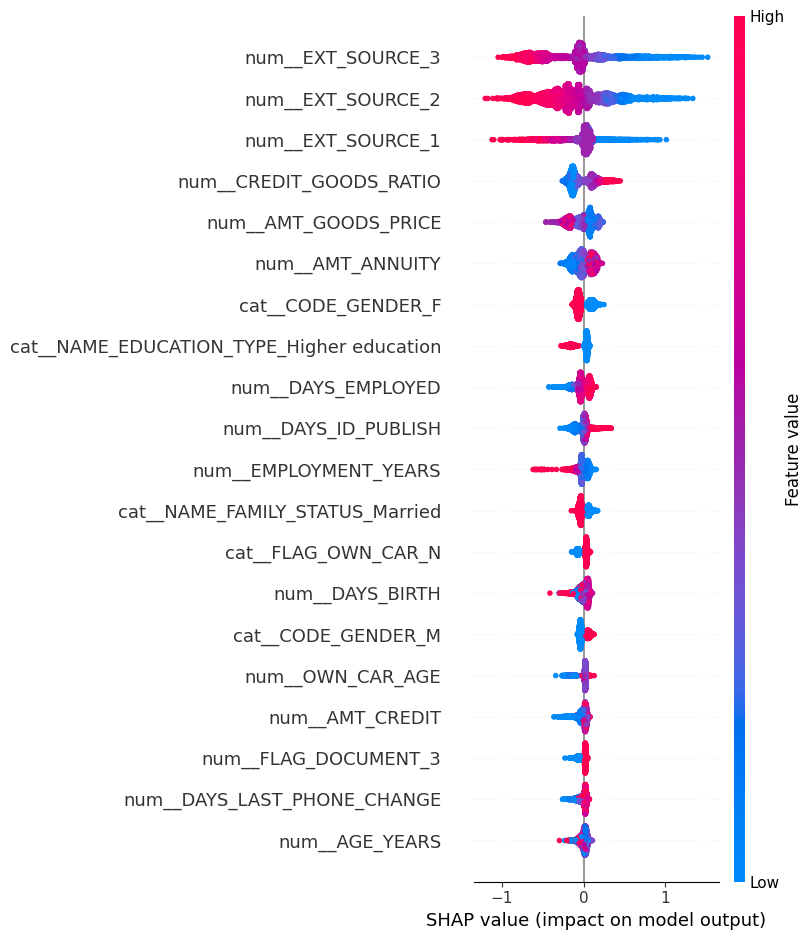

In [83]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names
)

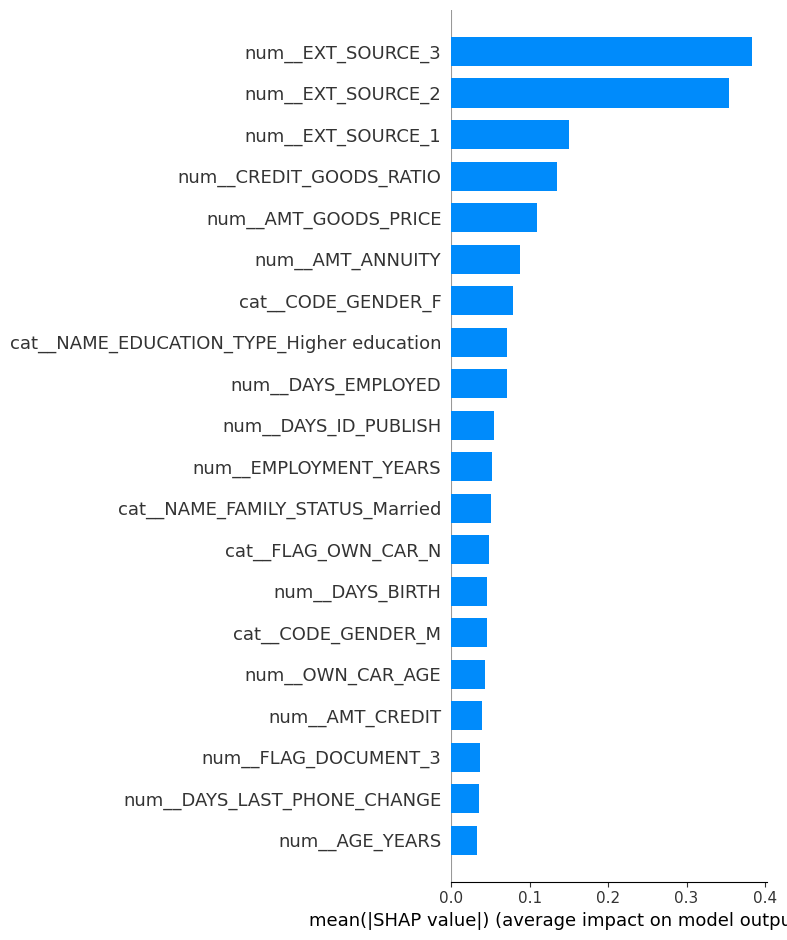

In [84]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar"
)

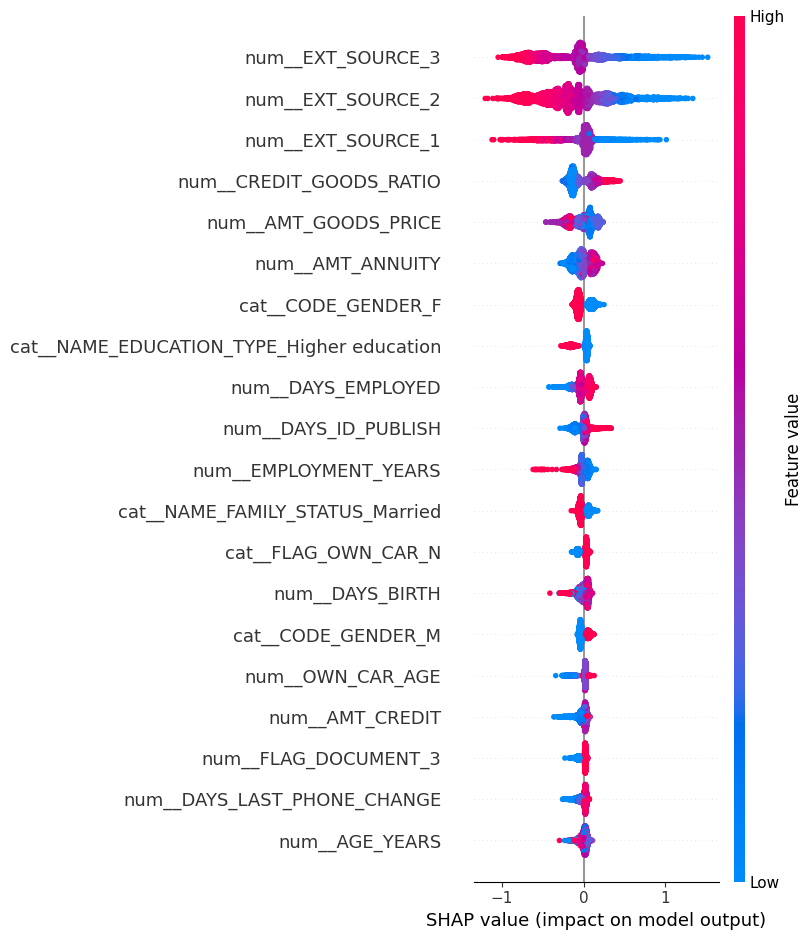

In [85]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names
)

In [86]:
# Select one applicant from validation data

applicant_index = 0

X_applicant = X_val_processed[applicant_index:applicant_index + 1]
y_actual = y_val.iloc[applicant_index]

print("Applicant selected")
print("Actual TARGET:", y_actual)

Applicant selected
Actual TARGET: 0


In [87]:
# Predict probability of payment difficulty

risk_probability = xgb_model.predict_proba(
    X_applicant
)[0, 1]

print(f"Risk Probability: {risk_probability:.4f}")
print(f"Risk Percentage: {risk_probability * 100:.2f}%")

Risk Probability: 0.3951
Risk Percentage: 39.51%


In [88]:
if risk_probability < 0.30:
    risk_level = "LOW"
elif risk_probability < 0.60:
    risk_level = "MEDIUM"
else:
    risk_level = "HIGH"

print("Risk Level:", risk_level)

Risk Level: MEDIUM


In [89]:
# Generate SHAP explanation for this applicant

applicant_shap = explainer(X_applicant)

print("SHAP explanation generated!")

SHAP explanation generated!


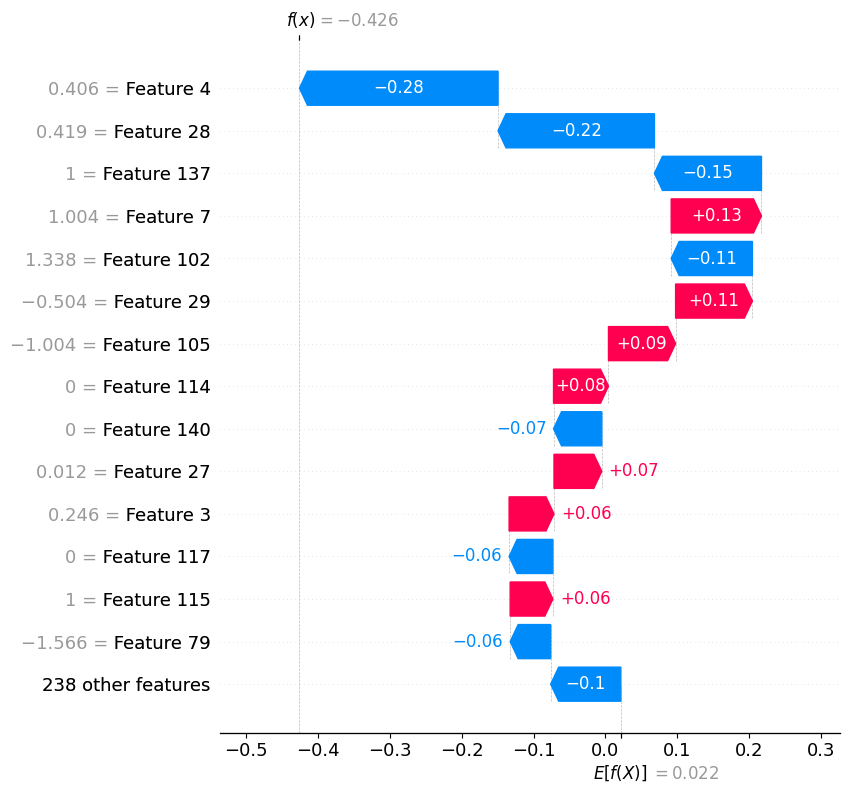

In [90]:
shap.plots.waterfall(
    applicant_shap[0],
    max_display=15
)

In [91]:
import numpy as np
import pandas as pd

# Get SHAP values for this applicant
applicant_shap_values = applicant_shap.values[0]

# Create explanation table
explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": applicant_shap_values
})

# Absolute SHAP value = strength of contribution
explanation["Impact"] = explanation["SHAP_Value"].abs()

# Sort by strongest contribution
explanation = explanation.sort_values(
    "Impact",
    ascending=False
)

explanation.head(15)

,Feature,SHAP_Value,Impact
4,num__AMT_GOODS_PRICE,-0.276358,0.276358
28,num__EXT_SOURCE_2,-0.217698,0.217698
137,cat__NAME_EDUCATION_TYPE_Higher education,-0.148935,0.148935
7,num__DAYS_EMPLOYED,0.125638,0.125638
102,num__AMT_REQ_CREDIT_BUREAU_QRT,-0.113026,0.113026
29,num__EXT_SOURCE_3,0.106891,0.106891
105,num__EMPLOYMENT_YEARS,0.093420,0.093420
114,cat__CODE_GENDER_F,0.076482,0.076482
140,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,-0.067151,0.067151
27,num__EXT_SOURCE_1,0.066503,0.066503


In [92]:
risk_increasing = explanation[
    explanation["SHAP_Value"] > 0
].head(5)

risk_decreasing = explanation[
    explanation["SHAP_Value"] < 0
].head(5)

print("Factors increasing predicted risk:")
display(risk_increasing[["Feature", "SHAP_Value"]])

print("\nFactors decreasing predicted risk:")
display(risk_decreasing[["Feature", "SHAP_Value"]])

Factors increasing predicted risk:


,Feature,SHAP_Value
7,num__DAYS_EMPLOYED,0.125638
29,num__EXT_SOURCE_3,0.106891
105,num__EMPLOYMENT_YEARS,0.093420
114,cat__CODE_GENDER_F,0.076482
27,num__EXT_SOURCE_1,0.066503



Factors decreasing predicted risk:


,Feature,SHAP_Value
4,num__AMT_GOODS_PRICE,-0.276358
28,num__EXT_SOURCE_2,-0.217698
137,cat__NAME_EDUCATION_TYPE_Higher education,-0.148935
102,num__AMT_REQ_CREDIT_BUREAU_QRT,-0.113026
140,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,-0.067151


In [93]:
print("=" * 50)
print("       CREDIT RISK APPLICANT ANALYSIS")
print("=" * 50)

print(f"Predicted Risk : {risk_probability * 100:.2f}%")
print(f"Risk Level     : {risk_level}")
print(f"Actual TARGET  : {y_actual}")

print("\nTop factors increasing predicted risk:")
for _, row in risk_increasing.iterrows():
    print(
        f"  ↑ {row['Feature']} "
        f"(SHAP: {row['SHAP_Value']:.4f})"
    )

print("\nTop factors decreasing predicted risk:")
for _, row in risk_decreasing.iterrows():
    print(
        f"  ↓ {row['Feature']} "
        f"(SHAP: {row['SHAP_Value']:.4f})"
    )

       CREDIT RISK APPLICANT ANALYSIS
Predicted Risk : 39.51%
Risk Level     : MEDIUM
Actual TARGET  : 0

Top factors increasing predicted risk:
  ↑ num__DAYS_EMPLOYED (SHAP: 0.1256)
  ↑ num__EXT_SOURCE_3 (SHAP: 0.1069)
  ↑ num__EMPLOYMENT_YEARS (SHAP: 0.0934)
  ↑ cat__CODE_GENDER_F (SHAP: 0.0765)
  ↑ num__EXT_SOURCE_1 (SHAP: 0.0665)

Top factors decreasing predicted risk:
  ↓ num__AMT_GOODS_PRICE (SHAP: -0.2764)
  ↓ num__EXT_SOURCE_2 (SHAP: -0.2177)
  ↓ cat__NAME_EDUCATION_TYPE_Higher education (SHAP: -0.1489)
  ↓ num__AMT_REQ_CREDIT_BUREAU_QRT (SHAP: -0.1130)
  ↓ cat__NAME_EDUCATION_TYPE_Secondary / secondary special (SHAP: -0.0672)


In [94]:
print("Feature 4  :", feature_names[4])
print("Feature 28 :", feature_names[28])
print("Feature 137:", feature_names[137])
print("Feature 102:", feature_names[102])
print("Feature 29 :", feature_names[29])
print("Feature 7  :", feature_names[7])
print("Feature 105:", feature_names[105])
print("Feature 114:", feature_names[114])

Feature 4  : num__AMT_GOODS_PRICE
Feature 28 : num__EXT_SOURCE_2
Feature 137: cat__NAME_EDUCATION_TYPE_Higher education
Feature 102: num__AMT_REQ_CREDIT_BUREAU_QRT
Feature 29 : num__EXT_SOURCE_3
Feature 7  : num__DAYS_EMPLOYED
Feature 105: num__EMPLOYMENT_YEARS
Feature 114: cat__CODE_GENDER_F


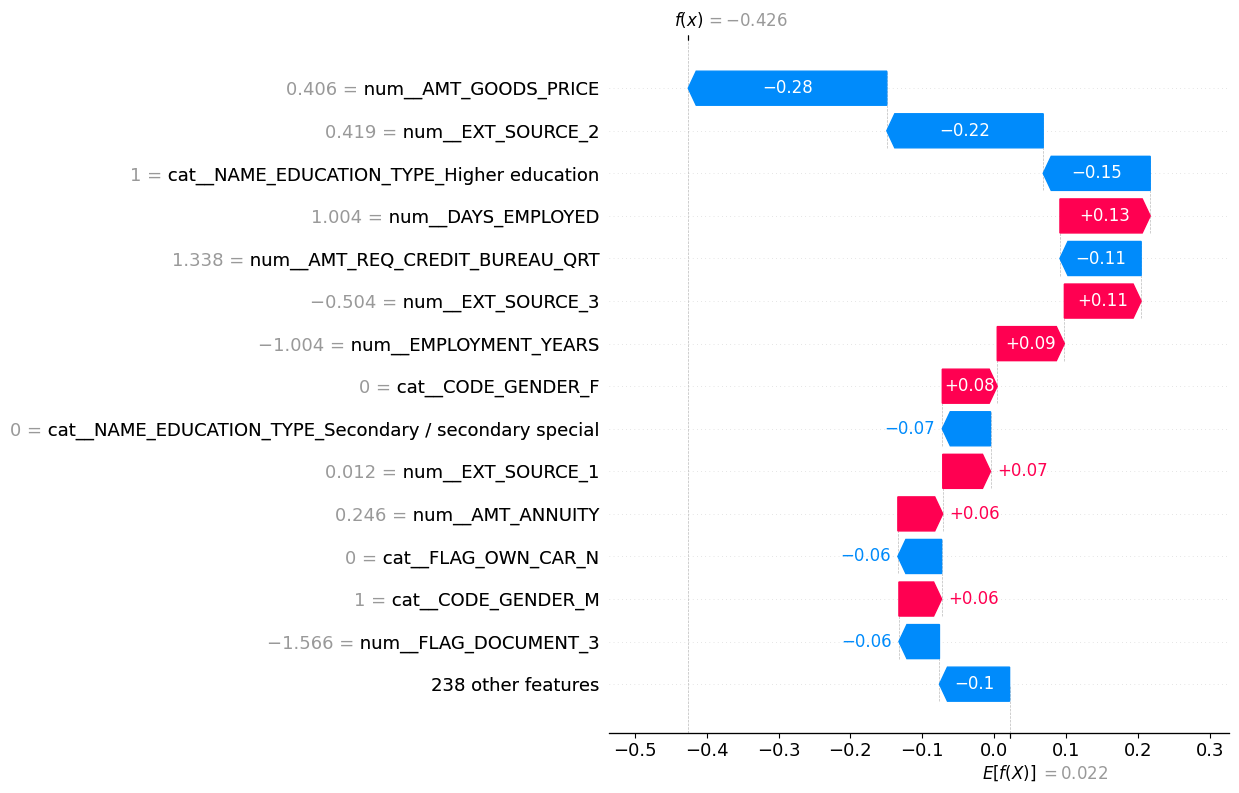

In [95]:
applicant_shap = explainer(
    X_applicant
)

applicant_shap.feature_names = feature_names

shap.plots.waterfall(
    applicant_shap[0],
    max_display=15
)

In [96]:
print("Feature 4  :", feature_names[4])
print("Feature 28 :", feature_names[28])
print("Feature 137:", feature_names[137])
print("Feature 102:", feature_names[102])
print("Feature 29 :", feature_names[29])
print("Feature 7  :", feature_names[7])
print("Feature 105:", feature_names[105])
print("Feature 114:", feature_names[114])

Feature 4  : num__AMT_GOODS_PRICE
Feature 28 : num__EXT_SOURCE_2
Feature 137: cat__NAME_EDUCATION_TYPE_Higher education
Feature 102: num__AMT_REQ_CREDIT_BUREAU_QRT
Feature 29 : num__EXT_SOURCE_3
Feature 7  : num__DAYS_EMPLOYED
Feature 105: num__EMPLOYMENT_YEARS
Feature 114: cat__CODE_GENDER_F


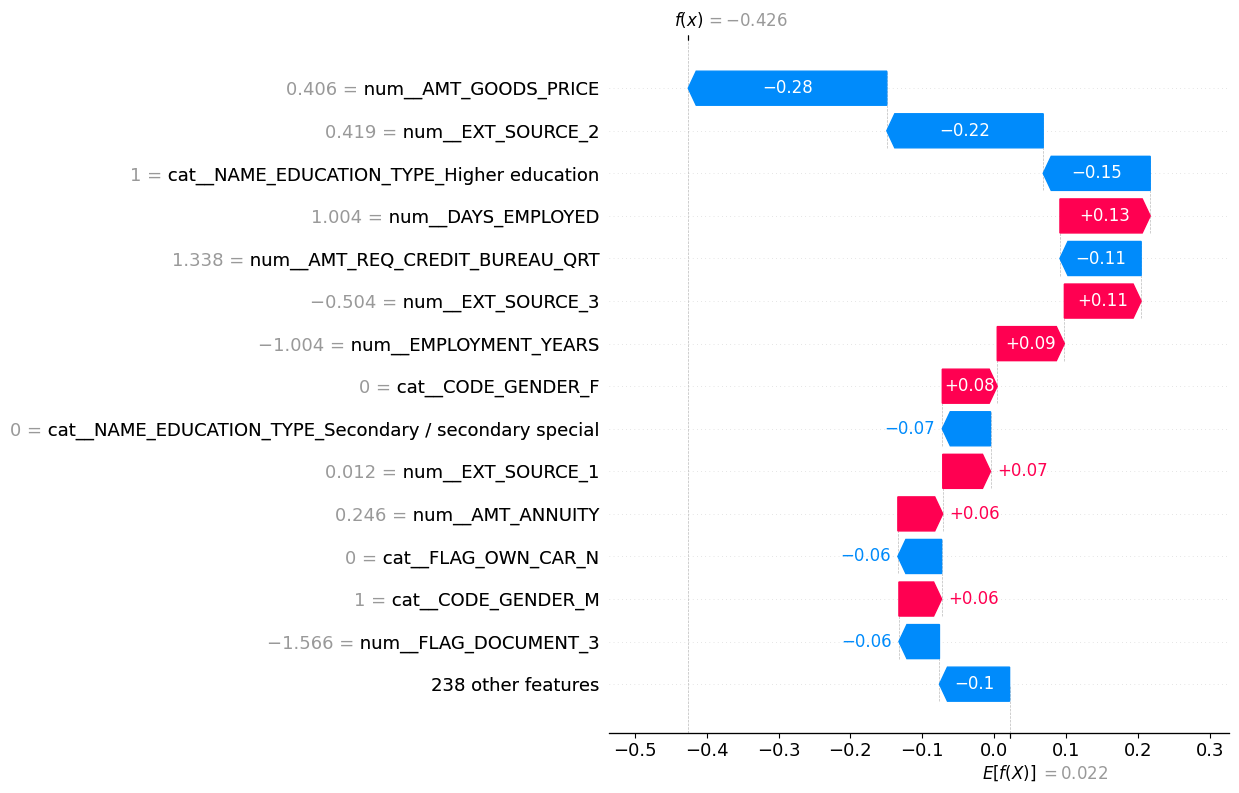

In [97]:
applicant_shap.feature_names = feature_names

shap.plots.waterfall(
    applicant_shap[0],
    max_display=15
)

# Create a clean explanation table

In [98]:
import pandas as pd

# Get SHAP values for the selected applicant
applicant_shap_values = applicant_shap.values[0]

# Create explanation dataframe
explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": applicant_shap_values
})

# Measure strength of each contribution
explanation["Impact"] = explanation["SHAP_Value"].abs()

# Strongest contributors first
explanation = explanation.sort_values(
    "Impact",
    ascending=False
)

# Show top 15
explanation.head(15)

,Feature,SHAP_Value,Impact
4,num__AMT_GOODS_PRICE,-0.276358,0.276358
28,num__EXT_SOURCE_2,-0.217698,0.217698
137,cat__NAME_EDUCATION_TYPE_Higher education,-0.148935,0.148935
7,num__DAYS_EMPLOYED,0.125638,0.125638
102,num__AMT_REQ_CREDIT_BUREAU_QRT,-0.113026,0.113026
29,num__EXT_SOURCE_3,0.106891,0.106891
105,num__EMPLOYMENT_YEARS,0.093420,0.093420
114,cat__CODE_GENDER_F,0.076482,0.076482
140,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,-0.067151,0.067151
27,num__EXT_SOURCE_1,0.066503,0.066503


In [99]:
risk_increasing = explanation[
    explanation["SHAP_Value"] > 0
].head(5)

risk_decreasing = explanation[
    explanation["SHAP_Value"] < 0
].head(5)

print("Factors increasing predicted risk:")
display(
    risk_increasing[["Feature", "SHAP_Value"]]
)

print("\nFactors decreasing predicted risk:")
display(
    risk_decreasing[["Feature", "SHAP_Value"]]
)

Factors increasing predicted risk:


,Feature,SHAP_Value
7,num__DAYS_EMPLOYED,0.125638
29,num__EXT_SOURCE_3,0.106891
105,num__EMPLOYMENT_YEARS,0.093420
114,cat__CODE_GENDER_F,0.076482
27,num__EXT_SOURCE_1,0.066503



Factors decreasing predicted risk:


,Feature,SHAP_Value
4,num__AMT_GOODS_PRICE,-0.276358
28,num__EXT_SOURCE_2,-0.217698
137,cat__NAME_EDUCATION_TYPE_Higher education,-0.148935
102,num__AMT_REQ_CREDIT_BUREAU_QRT,-0.113026
140,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,-0.067151


In [100]:
# Create clean feature names

explanation_clean = explanation.copy()

explanation_clean["Feature"] = (
    explanation_clean["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

explanation_clean.head(15)

,Feature,SHAP_Value,Impact
4,AMT_GOODS_PRICE,-0.276358,0.276358
28,EXT_SOURCE_2,-0.217698,0.217698
137,NAME_EDUCATION_TYPE_Higher education,-0.148935,0.148935
7,DAYS_EMPLOYED,0.125638,0.125638
102,AMT_REQ_CREDIT_BUREAU_QRT,-0.113026,0.113026
29,EXT_SOURCE_3,0.106891,0.106891
105,EMPLOYMENT_YEARS,0.093420,0.093420
114,CODE_GENDER_F,0.076482,0.076482
140,NAME_EDUCATION_TYPE_Secondary / secondary special,-0.067151,0.067151
27,EXT_SOURCE_1,0.066503,0.066503


In [101]:
explanation_clean = explanation.copy()

explanation_clean["Feature"] = (
    explanation_clean["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

explanation_clean["Direction"] = explanation_clean["SHAP_Value"].apply(
    lambda x: "Increases predicted risk"
    if x > 0
    else "Decreases predicted risk"
)

explanation_clean.head(15)

,Feature,SHAP_Value,Impact,Direction
4,AMT_GOODS_PRICE,-0.276358,0.276358,Decreases predicted risk
28,EXT_SOURCE_2,-0.217698,0.217698,Decreases predicted risk
137,NAME_EDUCATION_TYPE_Higher education,-0.148935,0.148935,Decreases predicted risk
7,DAYS_EMPLOYED,0.125638,0.125638,Increases predicted risk
102,AMT_REQ_CREDIT_BUREAU_QRT,-0.113026,0.113026,Decreases predicted risk
29,EXT_SOURCE_3,0.106891,0.106891,Increases predicted risk
105,EMPLOYMENT_YEARS,0.093420,0.093420,Increases predicted risk
114,CODE_GENDER_F,0.076482,0.076482,Increases predicted risk
140,NAME_EDUCATION_TYPE_Secondary / secondary special,-0.067151,0.067151,Decreases predicted risk
27,EXT_SOURCE_1,0.066503,0.066503,Increases predicted risk


# Phase 7 — Threshold Tuning

In [102]:
xgb_pred_proba = xgb_model.predict_proba(
    X_val_processed
)[:, 1]

print(xgb_pred_proba[:10])

[0.39514193 0.30827278 0.76333743 0.4140575  0.44095293 0.7037351
 0.1266088  0.08928452 0.85417426 0.530582  ]


In [103]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

In [104]:
thresholds = np.arange(0.10, 0.71, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        xgb_pred_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_results = pd.DataFrame(
    threshold_results
)

threshold_results

,Threshold,Precision,Recall,F1
0,0.10,0.083364,0.995972,0.153851
1,0.15,0.088344,0.985096,0.162147
2,0.20,0.095483,0.964753,0.173768
3,0.25,0.104516,0.935146,0.188018
4,0.30,0.114815,0.895468,0.203534
5,0.35,0.126815,0.851561,0.220754
6,0.40,0.140779,0.803021,0.239560
7,0.45,0.156049,0.743001,0.257927
8,0.50,0.171571,0.671702,0.273327
9,0.55,0.190666,0.596576,0.288976


In [105]:
best_threshold_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

print(best_threshold_row)

Threshold    0.650000
Precision    0.242998
Recall       0.431621
F1           0.310940
Name: 11, dtype: float64


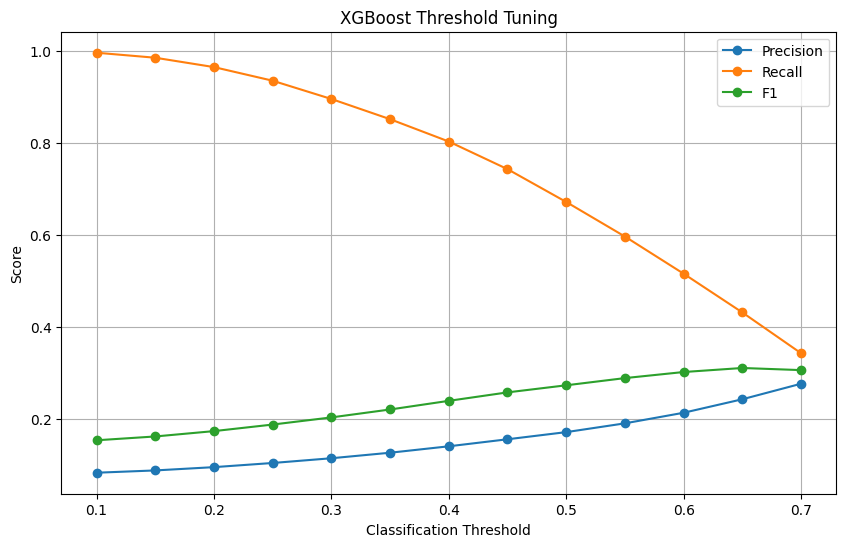

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoost Threshold Tuning")
plt.legend()
plt.grid(True)

plt.show()

In [107]:
best_threshold = best_threshold_row["Threshold"]

print(
    f"Selected threshold based on maximum validation F1: "
    f"{best_threshold:.2f}"
)

Selected threshold based on maximum validation F1: 0.65


In [108]:
for threshold in [0.50, best_threshold]:

    predictions = (
        xgb_pred_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1:        {f1:.4f}")


Threshold: 0.50
Precision: 0.1716
Recall:    0.6717
F1:        0.2733

Threshold: 0.65
Precision: 0.2430
Recall:    0.4316
F1:        0.3109


In [109]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_best = (
    xgb_pred_proba >= best_threshold
).astype(int)

cm = confusion_matrix(
    y_val,
    y_pred_best
)

print(cm)

[[49862  6676]
 [ 2822  2143]]


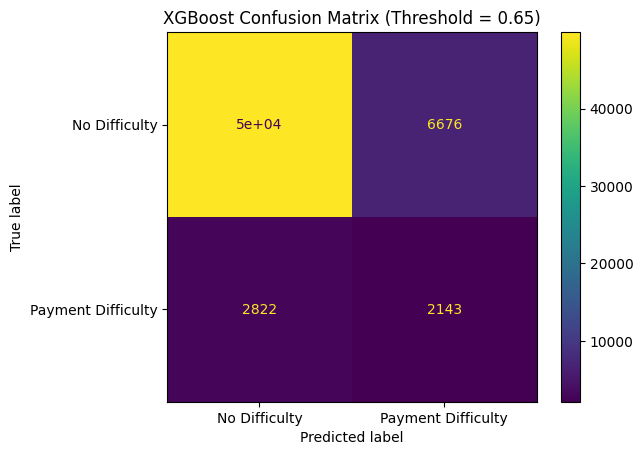

In [110]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Difficulty", "Payment Difficulty"]
).plot()

plt.title(
    f"XGBoost Confusion Matrix "
    f"(Threshold = {best_threshold:.2f})"
)

plt.show()

In [111]:
threshold_results

,Threshold,Precision,Recall,F1
0,0.10,0.083364,0.995972,0.153851
1,0.15,0.088344,0.985096,0.162147
2,0.20,0.095483,0.964753,0.173768
3,0.25,0.104516,0.935146,0.188018
4,0.30,0.114815,0.895468,0.203534
5,0.35,0.126815,0.851561,0.220754
6,0.40,0.140779,0.803021,0.239560
7,0.45,0.156049,0.743001,0.257927
8,0.50,0.171571,0.671702,0.273327
9,0.55,0.190666,0.596576,0.288976


In [112]:
y_pred_best = (xgb_pred_proba >= best_threshold).astype(int)

cm = confusion_matrix(y_val, y_pred_best)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives  :", tp)

[[49862  6676]
 [ 2822  2143]]
True Negatives : 49862
False Positives: 6676
False Negatives: 2822
True Positives  : 2143


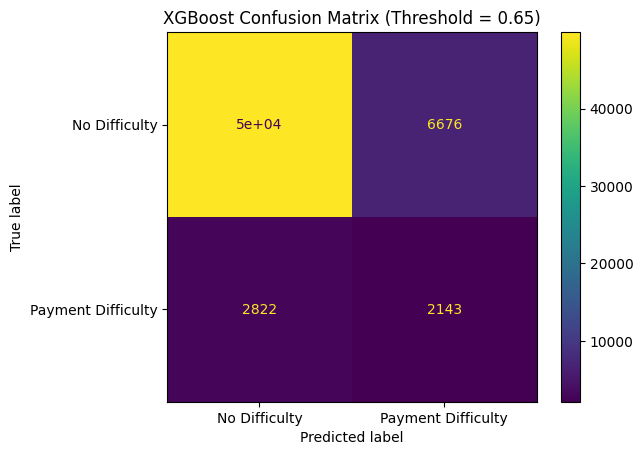

In [113]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Difficulty", "Payment Difficulty"]
).plot()

plt.title(f"XGBoost Confusion Matrix (Threshold = {best_threshold:.2f})")
plt.show()

# Classification Report

In [114]:
from sklearn.metrics import classification_report

y_pred_best = (xgb_pred_proba >= best_threshold).astype(int)

print("Classification Report at Threshold =", best_threshold)
print(
    classification_report(
        y_val,
        y_pred_best,
        target_names=["No Difficulty", "Payment Difficulty"],
        digits=4
    )
)

Classification Report at Threshold = 0.6500000000000001
                    precision    recall  f1-score   support

     No Difficulty     0.9464    0.8819    0.9130     56538
Payment Difficulty     0.2430    0.4316    0.3109      4965

          accuracy                         0.8456     61503
         macro avg     0.5947    0.6568    0.6120     61503
      weighted avg     0.8896    0.8456    0.8644     61503



# Store the final evaluation metrics

In [115]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_metrics = {
    "ROC-AUC": roc_auc_score(y_val, xgb_pred_proba),
    "PR-AUC": average_precision_score(y_val, xgb_pred_proba),
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_val, y_pred_best),
    "Precision": precision_score(y_val, y_pred_best),
    "Recall": recall_score(y_val, y_pred_best),
    "F1": f1_score(y_val, y_pred_best)
}

final_metrics

{'ROC-AUC': 0.7619121533354016,
 'PR-AUC': 0.25369589614769694,
 'Threshold': np.float64(0.6500000000000001),
 'Accuracy': 0.8455685088532267,
 'Precision': 0.24299807234380316,
 'Recall': 0.43162134944612285,
 'F1': 0.3109402205455601}

In [116]:
final_metrics_df = pd.DataFrame(
    [final_metrics]
)

final_metrics_df

,ROC-AUC,PR-AUC,Threshold,Accuracy,Precision,Recall,F1
0,0.761912,0.253696,0.65,0.845569,0.242998,0.431621,0.31094


# Save the selected threshold

In [117]:
import json

threshold_config = {
    "model": "XGBoost",
    "threshold": float(best_threshold),
    "selection_method": "Maximum F1 on validation set",
    "validation_range": "0.10 to 0.70"
}

with open("../models/threshold_config.json", "w") as f:
    json.dump(threshold_config, f, indent=4)

print("Threshold configuration saved successfully.")

Threshold configuration saved successfully.


In [118]:
with open("../models/threshold_config.json", "r") as f:
    loaded_threshold_config = json.load(f)

print(loaded_threshold_config)

{'model': 'XGBoost', 'threshold': 0.6500000000000001, 'selection_method': 'Maximum F1 on validation set', 'validation_range': '0.10 to 0.70'}


In [119]:
import joblib

joblib.dump(
    xgb_model,
    "../models/xgboost.pkl"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


# Test the prediction pipeline

In [120]:
import sys

sys.path.append("../src")

from predict import predict_risk

In [122]:
import pandas as pd

raw_data = pd.read_csv(
    "../data/raw/application_train.csv"
)

sample_applicant = raw_data.iloc[
    [0]
].copy()

In [123]:
import pandas as pd

raw_data = pd.read_csv(
    "../data/raw/application_train.csv"
)

In [124]:
sample_applicant = raw_data.iloc[[0]].copy()

In [125]:
raw_data.iloc[[0]]

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0


In [126]:
sample_dict = sample_applicant.iloc[0].to_dict()

sample_dict.pop("TARGET", None)

1

In [127]:
import json

api_request = {
    "applicant_data": sample_dict
}

print(json.dumps(api_request, indent=2))

{
  "applicant_data": {
    "SK_ID_CURR": 100002,
    "NAME_CONTRACT_TYPE": "Cash loans",
    "CODE_GENDER": "M",
    "FLAG_OWN_CAR": "N",
    "FLAG_OWN_REALTY": "Y",
    "CNT_CHILDREN": 0,
    "AMT_INCOME_TOTAL": 202500.0,
    "AMT_CREDIT": 406597.5,
    "AMT_ANNUITY": 24700.5,
    "AMT_GOODS_PRICE": 351000.0,
    "NAME_TYPE_SUITE": "Unaccompanied",
    "NAME_INCOME_TYPE": "Working",
    "NAME_EDUCATION_TYPE": "Secondary / secondary special",
    "NAME_FAMILY_STATUS": "Single / not married",
    "NAME_HOUSING_TYPE": "House / apartment",
    "REGION_POPULATION_RELATIVE": 0.018801,
    "DAYS_BIRTH": -9461,
    "DAYS_EMPLOYED": -637,
    "DAYS_REGISTRATION": -3648.0,
    "DAYS_ID_PUBLISH": -2120,
    "OWN_CAR_AGE": NaN,
    "FLAG_MOBIL": 1,
    "FLAG_EMP_PHONE": 1,
    "FLAG_WORK_PHONE": 0,
    "FLAG_CONT_MOBILE": 1,
    "FLAG_PHONE": 1,
    "FLAG_EMAIL": 0,
    "OCCUPATION_TYPE": "Laborers",
    "CNT_FAM_MEMBERS": 1.0,
    "REGION_RATING_CLIENT": 2,
    "REGION_RATING_CLIENT_W_CITY": 2,

In [128]:
result = predict_risk(
    sample_applicant
)

print(result)

{'probability': 0.8736, 'threshold': 0.65, 'prediction': 1, 'risk_level': 'Payment Difficulty', 'top_risk_factors': [{'feature': 'External Credit Score 3', 'shap_value': 0.771135, 'impact': 0.771135, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 1', 'shap_value': 0.496679, 'impact': 0.496679, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 2', 'shap_value': 0.278826, 'impact': 0.278826, 'direction': 'Increases predicted risk'}, {'feature': 'Goods Price', 'shap_value': 0.151598, 'impact': 0.151598, 'direction': 'Increases predicted risk'}, {'feature': 'DEF_30_CNT_SOCIAL_CIRCLE', 'shap_value': 0.107871, 'impact': 0.107871, 'direction': 'Increases predicted risk'}], 'top_protective_factors': [{'feature': 'DAYS_BIRTH', 'shap_value': -0.202285, 'impact': 0.202285, 'direction': 'Decreases predicted risk'}, {'feature': 'AGE_YEARS', 'shap_value': -0.099226, 'impact': 0.099226, 'direction': 'Decreases predicted risk'}, {'feature': 'Car

In [129]:
sample_applicants = raw_data.iloc[
    0:5
].copy()

for i in range(len(sample_applicants)):

    applicant = sample_applicants.iloc[
        [i]
    ]

    result = predict_risk(
        applicant
    )

    print(
        f"Applicant {i}:",
        result
    )

Applicant 0: {'probability': 0.8736, 'threshold': 0.65, 'prediction': 1, 'risk_level': 'Payment Difficulty', 'top_risk_factors': [{'feature': 'External Credit Score 3', 'shap_value': 0.771135, 'impact': 0.771135, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 1', 'shap_value': 0.496679, 'impact': 0.496679, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 2', 'shap_value': 0.278826, 'impact': 0.278826, 'direction': 'Increases predicted risk'}, {'feature': 'Goods Price', 'shap_value': 0.151598, 'impact': 0.151598, 'direction': 'Increases predicted risk'}, {'feature': 'DEF_30_CNT_SOCIAL_CIRCLE', 'shap_value': 0.107871, 'impact': 0.107871, 'direction': 'Increases predicted risk'}], 'top_protective_factors': [{'feature': 'DAYS_BIRTH', 'shap_value': -0.202285, 'impact': 0.202285, 'direction': 'Decreases predicted risk'}, {'feature': 'AGE_YEARS', 'shap_value': -0.099226, 'impact': 0.099226, 'direction': 'Decreases predicted risk'}, {'f

In [130]:
from predict import predict_risk

In [131]:
print("Probability:", result["probability"])
print("Threshold:", result["threshold"])
print("Risk Level:", result["risk_level"])

print("\nTop Risk Factors:")

for factor in result["top_risk_factors"]:
    print(
        factor["feature"],
        "→",
        factor["shap_value"]
    )

print("\nTop Protective Factors:")

for factor in result["top_protective_factors"]:
    print(
        factor["feature"],
        "→",
        factor["shap_value"]
    )

Probability: 0.5765
Threshold: 0.65
Risk Level: No Difficulty

Top Risk Factors:
External Credit Score 2 → 0.356479
Gender: Female → 0.180067
Family Status: Married → 0.111923
Gender: Male → 0.087105
Does Not Own a Car → 0.055709

Top Protective Factors:
Credit-to-Goods Price Ratio → -0.125541
Car Age → -0.108449
Occupation: Core Staff → -0.107719
Document 3 Provided → -0.097923
Employment Days → -0.071913


In [132]:
import importlib
import predict

importlib.reload(predict)

from predict import predict_risk

In [133]:
result = predict_risk(sample_applicant)

In [134]:
print(result)

{'probability': 0.8736, 'threshold': 0.65, 'prediction': 1, 'risk_level': 'Payment Difficulty', 'top_risk_factors': [{'feature': 'External Credit Score 3', 'shap_value': 0.771135, 'impact': 0.771135, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 1', 'shap_value': 0.496679, 'impact': 0.496679, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 2', 'shap_value': 0.278826, 'impact': 0.278826, 'direction': 'Increases predicted risk'}, {'feature': 'Goods Price', 'shap_value': 0.151598, 'impact': 0.151598, 'direction': 'Increases predicted risk'}, {'feature': 'DEF_30_CNT_SOCIAL_CIRCLE', 'shap_value': 0.107871, 'impact': 0.107871, 'direction': 'Increases predicted risk'}], 'top_protective_factors': [{'feature': 'DAYS_BIRTH', 'shap_value': -0.202285, 'impact': 0.202285, 'direction': 'Decreases predicted risk'}, {'feature': 'AGE_YEARS', 'shap_value': -0.099226, 'impact': 0.099226, 'direction': 'Decreases predicted risk'}, {'feature': 'Car

In [135]:
print("Probability:", result["probability"])
print("Threshold:", result["threshold"])
print("Risk Level:", result["risk_level"])

print("\nTop Risk Factors:")

for factor in result["top_risk_factors"]:
    print(
        f"- {factor['feature']}: "
        f"{factor['shap_value']:.4f} "
        f"({factor['direction']})"
    )

print("\nTop Protective Factors:")

for factor in result["top_protective_factors"]:
    print(
        f"- {factor['feature']}: "
        f"{factor['shap_value']:.4f} "
        f"({factor['direction']})"
    )

Probability: 0.8736
Threshold: 0.65
Risk Level: Payment Difficulty

Top Risk Factors:
- External Credit Score 3: 0.7711 (Increases predicted risk)
- External Credit Score 1: 0.4967 (Increases predicted risk)
- External Credit Score 2: 0.2788 (Increases predicted risk)
- Goods Price: 0.1516 (Increases predicted risk)
- DEF_30_CNT_SOCIAL_CIRCLE: 0.1079 (Increases predicted risk)

Top Protective Factors:
- DAYS_BIRTH: -0.2023 (Decreases predicted risk)
- AGE_YEARS: -0.0992 (Decreases predicted risk)
- Car Age: -0.0769 (Decreases predicted risk)
- Annuity-to-Income Ratio: -0.0470 (Decreases predicted risk)
- Credit-to-Goods Price Ratio: -0.0346 (Decreases predicted risk)


In [136]:
import pandas as pd

raw_data = pd.read_csv(
    "../data/raw/application_train.csv"
)

sample_applicant = raw_data.iloc[[0]].copy()

In [137]:
sample_applicant.shape

(1, 122)

In [138]:
sample_applicant.head()


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0


In [139]:
import sys

sys.path.append("../src")

from predict import predict_risk

In [140]:
result = predict_risk(sample_applicant)

print(result)

{'probability': 0.8736, 'threshold': 0.65, 'prediction': 1, 'risk_level': 'Payment Difficulty', 'top_risk_factors': [{'feature': 'External Credit Score 3', 'shap_value': 0.771135, 'impact': 0.771135, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 1', 'shap_value': 0.496679, 'impact': 0.496679, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 2', 'shap_value': 0.278826, 'impact': 0.278826, 'direction': 'Increases predicted risk'}, {'feature': 'Goods Price', 'shap_value': 0.151598, 'impact': 0.151598, 'direction': 'Increases predicted risk'}, {'feature': 'DEF_30_CNT_SOCIAL_CIRCLE', 'shap_value': 0.107871, 'impact': 0.107871, 'direction': 'Increases predicted risk'}], 'top_protective_factors': [{'feature': 'DAYS_BIRTH', 'shap_value': -0.202285, 'impact': 0.202285, 'direction': 'Decreases predicted risk'}, {'feature': 'AGE_YEARS', 'shap_value': -0.099226, 'impact': 0.099226, 'direction': 'Decreases predicted risk'}, {'feature': 'Car

In [141]:
sample_dict = sample_applicant.iloc[0].to_dict()

sample_dict.pop("TARGET", None)

1

In [142]:
import json

api_request = {
    "applicant_data": sample_dict
}

print(json.dumps(api_request, indent=2))

{
  "applicant_data": {
    "SK_ID_CURR": 100002,
    "NAME_CONTRACT_TYPE": "Cash loans",
    "CODE_GENDER": "M",
    "FLAG_OWN_CAR": "N",
    "FLAG_OWN_REALTY": "Y",
    "CNT_CHILDREN": 0,
    "AMT_INCOME_TOTAL": 202500.0,
    "AMT_CREDIT": 406597.5,
    "AMT_ANNUITY": 24700.5,
    "AMT_GOODS_PRICE": 351000.0,
    "NAME_TYPE_SUITE": "Unaccompanied",
    "NAME_INCOME_TYPE": "Working",
    "NAME_EDUCATION_TYPE": "Secondary / secondary special",
    "NAME_FAMILY_STATUS": "Single / not married",
    "NAME_HOUSING_TYPE": "House / apartment",
    "REGION_POPULATION_RELATIVE": 0.018801,
    "DAYS_BIRTH": -9461,
    "DAYS_EMPLOYED": -637,
    "DAYS_REGISTRATION": -3648.0,
    "DAYS_ID_PUBLISH": -2120,
    "OWN_CAR_AGE": NaN,
    "FLAG_MOBIL": 1,
    "FLAG_EMP_PHONE": 1,
    "FLAG_WORK_PHONE": 0,
    "FLAG_CONT_MOBILE": 1,
    "FLAG_PHONE": 1,
    "FLAG_EMAIL": 0,
    "OCCUPATION_TYPE": "Laborers",
    "CNT_FAM_MEMBERS": 1.0,
    "REGION_RATING_CLIENT": 2,
    "REGION_RATING_CLIENT_W_CITY": 2,

In [143]:
import pandas as pd

raw_data = pd.read_csv(
    "../data/raw/application_train.csv"
)

sample_applicant = raw_data.iloc[[0]].copy()

In [144]:
import sys

sys.path.append("../src")

from predict import predict_risk

In [145]:
result = predict_risk(sample_applicant)

print(result)

{'probability': 0.8736, 'threshold': 0.65, 'prediction': 1, 'risk_level': 'Payment Difficulty', 'top_risk_factors': [{'feature': 'External Credit Score 3', 'shap_value': 0.771135, 'impact': 0.771135, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 1', 'shap_value': 0.496679, 'impact': 0.496679, 'direction': 'Increases predicted risk'}, {'feature': 'External Credit Score 2', 'shap_value': 0.278826, 'impact': 0.278826, 'direction': 'Increases predicted risk'}, {'feature': 'Goods Price', 'shap_value': 0.151598, 'impact': 0.151598, 'direction': 'Increases predicted risk'}, {'feature': 'DEF_30_CNT_SOCIAL_CIRCLE', 'shap_value': 0.107871, 'impact': 0.107871, 'direction': 'Increases predicted risk'}], 'top_protective_factors': [{'feature': 'DAYS_BIRTH', 'shap_value': -0.202285, 'impact': 0.202285, 'direction': 'Decreases predicted risk'}, {'feature': 'AGE_YEARS', 'shap_value': -0.099226, 'impact': 0.099226, 'direction': 'Decreases predicted risk'}, {'feature': 'Car

# JSON request

In [146]:
sample_dict = sample_applicant.iloc[0].to_dict()

# TARGET is the value we are trying to predict,
# so it must not be sent to the API.
sample_dict.pop("TARGET", None)

1

In [147]:
import json

api_request = {
    "applicant_data": sample_dict
}

print(json.dumps(api_request, indent=2))

{
  "applicant_data": {
    "SK_ID_CURR": 100002,
    "NAME_CONTRACT_TYPE": "Cash loans",
    "CODE_GENDER": "M",
    "FLAG_OWN_CAR": "N",
    "FLAG_OWN_REALTY": "Y",
    "CNT_CHILDREN": 0,
    "AMT_INCOME_TOTAL": 202500.0,
    "AMT_CREDIT": 406597.5,
    "AMT_ANNUITY": 24700.5,
    "AMT_GOODS_PRICE": 351000.0,
    "NAME_TYPE_SUITE": "Unaccompanied",
    "NAME_INCOME_TYPE": "Working",
    "NAME_EDUCATION_TYPE": "Secondary / secondary special",
    "NAME_FAMILY_STATUS": "Single / not married",
    "NAME_HOUSING_TYPE": "House / apartment",
    "REGION_POPULATION_RELATIVE": 0.018801,
    "DAYS_BIRTH": -9461,
    "DAYS_EMPLOYED": -637,
    "DAYS_REGISTRATION": -3648.0,
    "DAYS_ID_PUBLISH": -2120,
    "OWN_CAR_AGE": NaN,
    "FLAG_MOBIL": 1,
    "FLAG_EMP_PHONE": 1,
    "FLAG_WORK_PHONE": 0,
    "FLAG_CONT_MOBILE": 1,
    "FLAG_PHONE": 1,
    "FLAG_EMAIL": 0,
    "OCCUPATION_TYPE": "Laborers",
    "CNT_FAM_MEMBERS": 1.0,
    "REGION_RATING_CLIENT": 2,
    "REGION_RATING_CLIENT_W_CITY": 2,